In [1]:
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.cluster import contingency_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from scipy.optimize import linear_sum_assignment
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

#Exercise 3

In [2]:
df=pd.read_csv('bedtime_screentime_sleep_debt.csv')
df.head()

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names and data types
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicated rows
print("\nDuplicated Rows:", df.duplicated().sum())

Dataset Shape: (8500, 18)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   object 
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   object 
 3   occupation_type           8500 non-null   object 
 4   chronotype                8500 non-null   object 
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   object 
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct 

### Data Preprocessing
We will now prepare our data for machine learning. This process consists of handling missing values, splitting our data into training, validation, and testing sets, scaling numerical features, and encoding categorical features.

In [3]:
# Drop unnecessary columns
df = df.drop(columns=[
    "user_id",
    "next_day_fatigue_score"
])

# Check updated dataset
print("Updated Dataset Shape:", df.shape)

display(df.head())

Updated Dataset Shape: (8500, 16)


,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,sleep_debt_category
0,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,Severe Sleep Debt
1,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,Severe Sleep Debt
2,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,Severe Sleep Debt
3,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,Mild Deficit
4,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,Moderate Debt


In [4]:
# Input features
X = df.drop(columns=["sleep_debt_category"])

# Target variable
y = df["sleep_debt_category"]

print("Input features:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.name)

Input features:
['age', 'gender', 'occupation_type', 'chronotype', 'bedtime_phone_minutes', 'primary_bedtime_app', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes']

Target variable:
sleep_debt_category


###Exploratory Data Analysis

In [5]:
# Summary statistics for numerical variables
display(df.describe())

# Summary statistics for categorical variables
display(df.describe(include="object"))

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes
count,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000
mean,34.355647,59.250000,55.153882,0.467765,33.222471,35.701412,40.671471,6.266209,21.735741,19.105859,2.766000
std,11.584259,36.931991,19.850550,0.498989,51.935645,20.819390,17.444914,1.446258,3.069377,2.546459,1.695407
min,18.000000,1.000000,10.000000,0.000000,0.000000,0.000000,6.000000,3.200000,8.100000,9.600000,0.000000
25%,25.000000,31.000000,42.000000,0.000000,0.000000,21.000000,28.200000,5.240000,19.700000,17.400000,2.000000
50%,32.000000,51.000000,55.000000,0.000000,0.000000,35.000000,37.600000,6.330000,21.900000,19.100000,3.000000
75%,42.000000,79.000000,69.000000,1.000000,55.000000,50.000000,49.700000,7.350000,23.900000,20.800000,4.000000
max,65.000000,180.000000,100.000000,1.000000,250.000000,112.000000,123.300000,9.800000,28.000000,27.000000,7.000000


,gender,occupation_type,chronotype,primary_bedtime_app,sleep_debt_category
count,8500,8500,8500,8500,8500
unique,3,5,3,6,4
top,Female,Corporate 9-to-5,Intermediate,TikTok / Reels,Moderate Debt
freq,4347,2838,3880,2198,4462


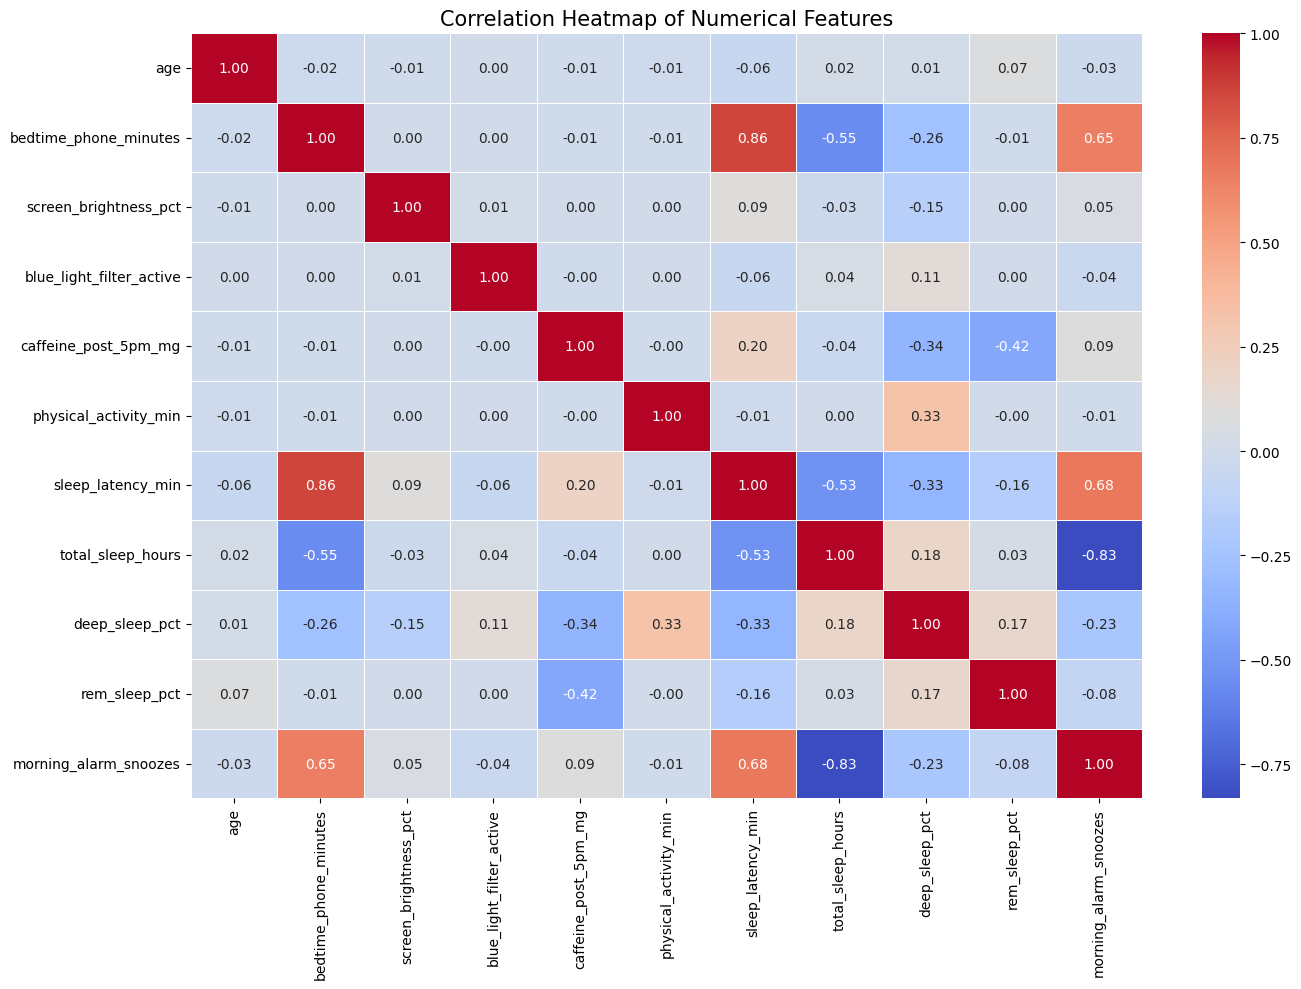

In [6]:
# Calculate correlation matrix
correlation_matrix = df.select_dtypes(
    include=["int64", "float64"]
).drop(columns=["user_id"], errors="ignore").corr()

# Plot heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features", fontsize=15)

plt.tight_layout()
plt.show()

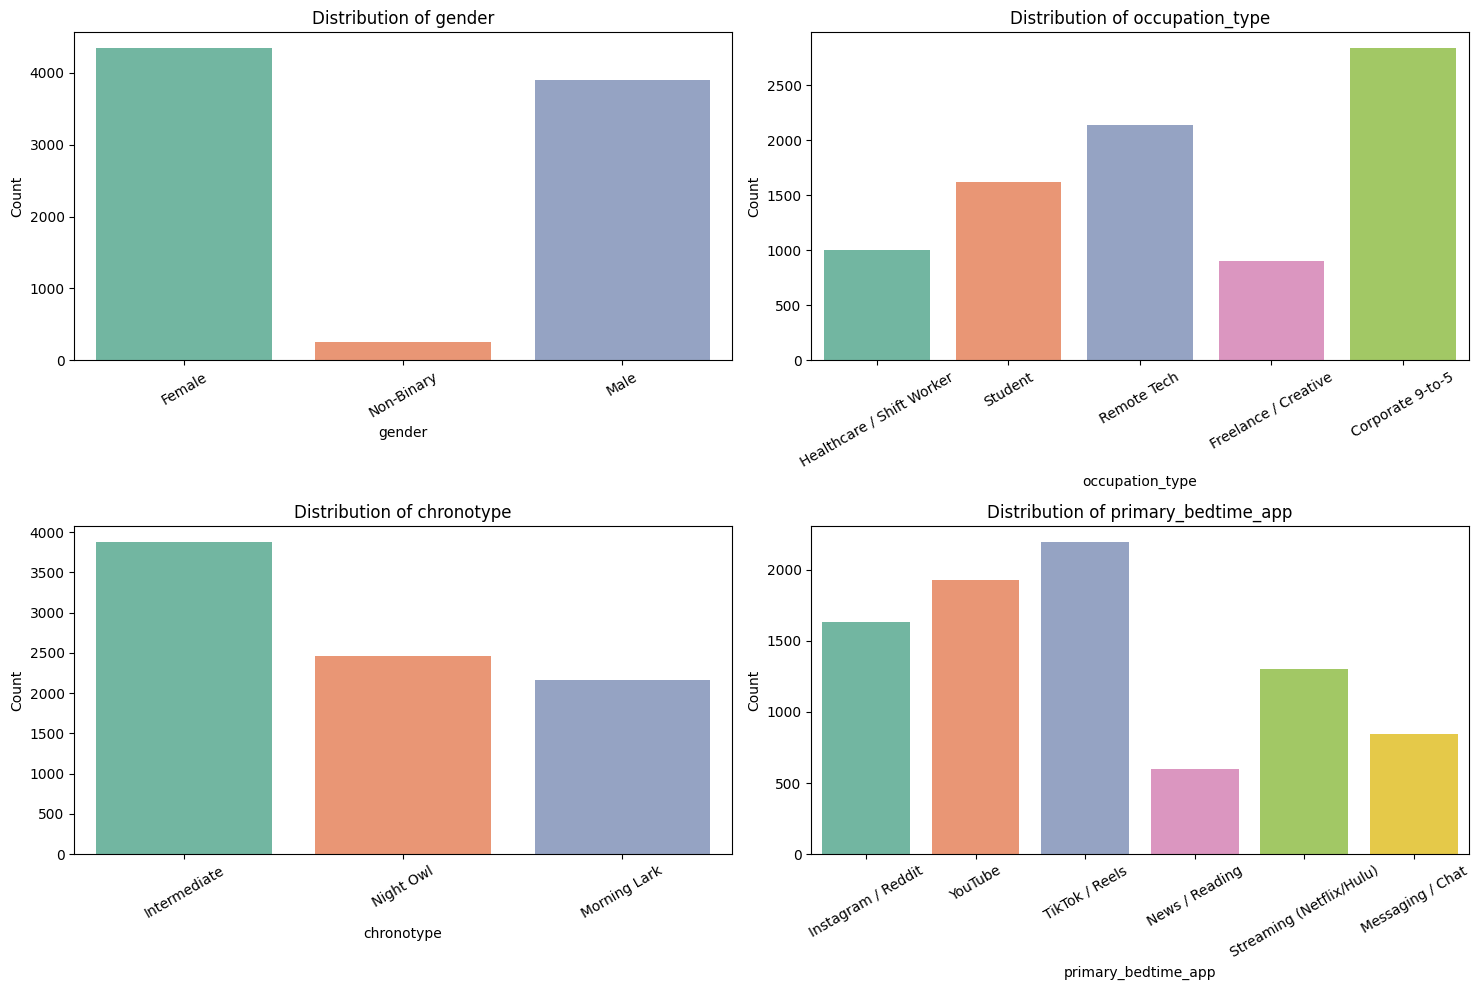

In [7]:
categorical_features = [
    "gender",
    "occupation_type",
    "chronotype",
    "primary_bedtime_app"
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for feature, ax in zip(categorical_features, axes.flatten()):

    sns.countplot(
        data=df,
        x=feature,
        hue=feature,
        palette="Set2",
        legend=False,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

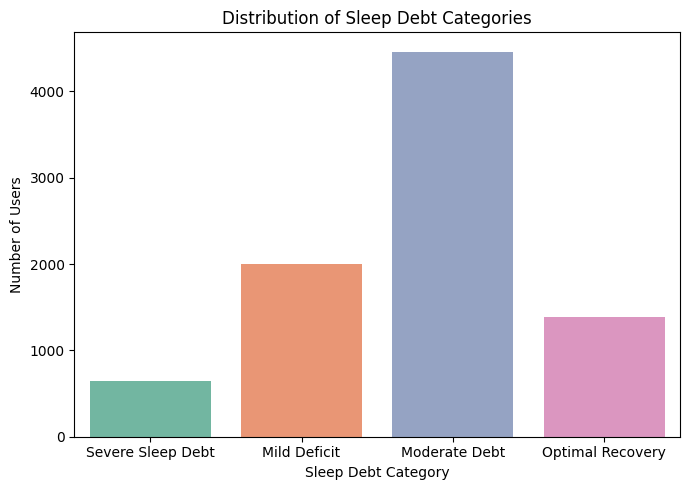

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="sleep_debt_category",
    hue="sleep_debt_category",
    palette="Set2",
    legend=False
)

plt.title("Distribution of Sleep Debt Categories")
plt.xlabel("Sleep Debt Category")
plt.ylabel("Number of Users")

plt.tight_layout()
plt.show()

###Preprocessing Steps + Splitting

In [9]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

print("Target categories:")
print(label_encoder.classes_)

print("\nNumber of features:", X.shape[1])

Target categories:
['Mild Deficit' 'Moderate Debt' 'Optimal Recovery' 'Severe Sleep Debt']

Number of features: 15


In [10]:
# First split: 60% training, 40% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Second split: 20% validation, 20% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

Training set: (5100, 15)
Validation set: (1700, 15)
Testing set: (1700, 15)


In [11]:
#ENCODIN
# Identify numerical and categorical features
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and testing data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

Training: (5100, 28)
Validation: (1700, 28)
Testing: (1700, 28)


In [12]:
print("Training Set Class Distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nValidation Set Class Distribution:")
print(pd.Series(y_val).value_counts().sort_index())

print("\nTesting Set Class Distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training Set Class Distribution:
0    1203
1    2677
2     832
3     388
Name: count, dtype: int64

Validation Set Class Distribution:
0    400
1    893
2    277
3    130
Name: count, dtype: int64

Testing Set Class Distribution:
0    401
1    892
2    278
3    129
Name: count, dtype: int64


In [13]:
torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [14]:
# Convert input features to dense arrays if necessary
def to_dense_array(data):
    if hasattr(data, "toarray"):
        return data.toarray()
    return np.asarray(data)

# Convert features
X_train_tensor = torch.tensor(
    to_dense_array(X_train_processed),
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    to_dense_array(X_val_processed),
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    to_dense_array(X_test_processed),
    dtype=torch.float32
)

# Convert target labels
y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.long
)

y_val_tensor = torch.tensor(
    y_val,
    dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.long
)

print("Training:", X_train_tensor.shape)
print("Validation:", X_val_tensor.shape)
print("Testing:", X_test_tensor.shape)

Training: torch.Size([5100, 28])
Validation: torch.Size([1700, 28])
Testing: torch.Size([1700, 28])


In [15]:
input_size = X_train_tensor.shape[1]

num_classes = len(np.unique(y_train))

print("Number of input neurons:", input_size)
print("Number of output neurons:", num_classes)

Number of input neurons: 28
Number of output neurons: 4


In [16]:
batch_size = 32

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [17]:
class SleepDebtNN(nn.Module):

    def __init__(self, input_size, num_classes):

        super(SleepDebtNN, self).__init__()

        self.network = nn.Sequential(

            # Input to hidden layer 1
            nn.Linear(input_size, 64),
            nn.ReLU(),

            # Hidden layer 1 to hidden layer 2
            nn.Linear(64, 32),
            nn.ReLU(),

            # Hidden layer 2 to output
            nn.Linear(32, num_classes)

        )

    def forward(self, x):

        return self.network(x)

In [18]:
model = SleepDebtNN(
    input_size,
    num_classes
).to(device)

print(model)

SleepDebtNN(
  (network): Sequential(
    (0): Linear(in_features=28, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=4, bias=True)
  )
)


In [19]:
#define the loss function and optimiser
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [20]:
#training + validation
num_epochs = 100

train_losses = []
val_losses = []
test_losses = []

for epoch in range(num_epochs):

    model.train()

    running_train_loss = 0.0

    for inputs, labels in train_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item() * inputs.size(0)

    epoch_train_loss = (
        running_train_loss / len(train_dataset)
    )

    model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for inputs, labels in val_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * inputs.size(0)

    epoch_val_loss = (
        running_val_loss / len(val_dataset)
    )

    running_test_loss = 0.0

    with torch.no_grad():

        for inputs, labels in test_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_test_loss += loss.item() * inputs.size(0)

    epoch_test_loss = (
        running_test_loss / len(test_dataset)
    )

    # Store losses
    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    test_losses.append(epoch_test_loss)

    # Display progress
    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch+1}/{num_epochs}] "
            f"| Training Loss: {epoch_train_loss:.4f} "
            f"| Validation Loss: {epoch_val_loss:.4f}"
            f"| Test Loss: {epoch_test_loss:.4f}"
        )

Epoch [10/100] | Training Loss: 0.0888 | Validation Loss: 0.0877| Test Loss: 0.1002
Epoch [20/100] | Training Loss: 0.0614 | Validation Loss: 0.0767| Test Loss: 0.0927
Epoch [30/100] | Training Loss: 0.0485 | Validation Loss: 0.0778| Test Loss: 0.0991
Epoch [40/100] | Training Loss: 0.0441 | Validation Loss: 0.0844| Test Loss: 0.1018
Epoch [50/100] | Training Loss: 0.0383 | Validation Loss: 0.0968| Test Loss: 0.1121
Epoch [60/100] | Training Loss: 0.0322 | Validation Loss: 0.1099| Test Loss: 0.1349
Epoch [70/100] | Training Loss: 0.0304 | Validation Loss: 0.1097| Test Loss: 0.1371
Epoch [80/100] | Training Loss: 0.0261 | Validation Loss: 0.1327| Test Loss: 0.1484
Epoch [90/100] | Training Loss: 0.0206 | Validation Loss: 0.1303| Test Loss: 0.1558
Epoch [100/100] | Training Loss: 0.0428 | Validation Loss: 0.1874| Test Loss: 0.2334


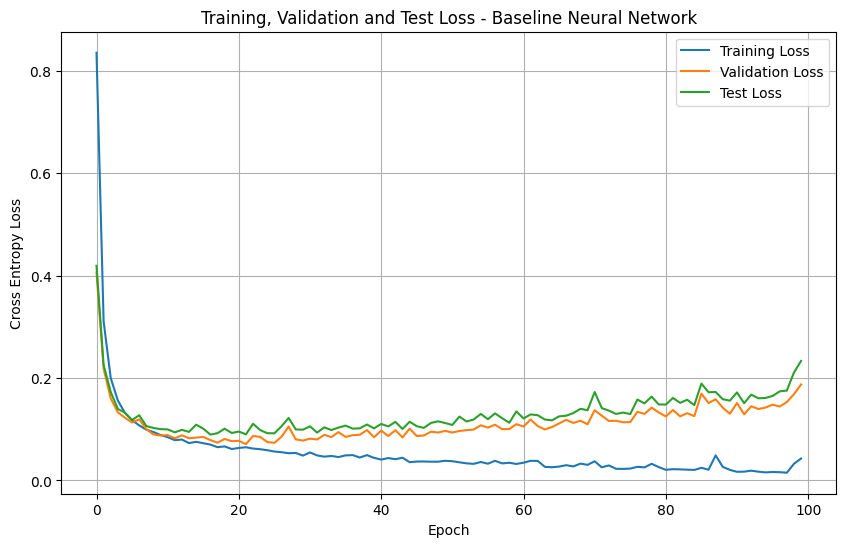

In [21]:
#visualise training and validation losses
plt.figure(figsize=(10, 6))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.plot(
    test_losses,
    label="Test Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")

plt.title(
    "Training, Validation and Test Loss - Baseline Neural Network"
)

plt.legend()
plt.grid(True)

plt.show()

In [22]:
#evaluate the trained model
def evaluate_model(model, loader):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for inputs, labels in loader:

            inputs = inputs.to(device)

            outputs = model(inputs)

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.numpy()
            )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    return accuracy, all_labels, all_predictions

In [23]:
#calculate training, validation, and testing accuracy
train_acc, _, _ = evaluate_model(
    model,
    train_loader
)

val_acc, _, _ = evaluate_model(
    model,
    val_loader
)

test_acc, y_true, y_pred = evaluate_model(
    model,
    test_loader
)

print("Model Performance")
print("-------------------------")

print(f"Training Accuracy:   {train_acc*100:.2f}%")
print(f"Validation Accuracy: {val_acc*100:.2f}%")
print(f"Testing Accuracy:    {test_acc*100:.2f}%")

Model Performance
-------------------------
Training Accuracy:   98.76%
Validation Accuracy: 95.06%
Testing Accuracy:    94.24%


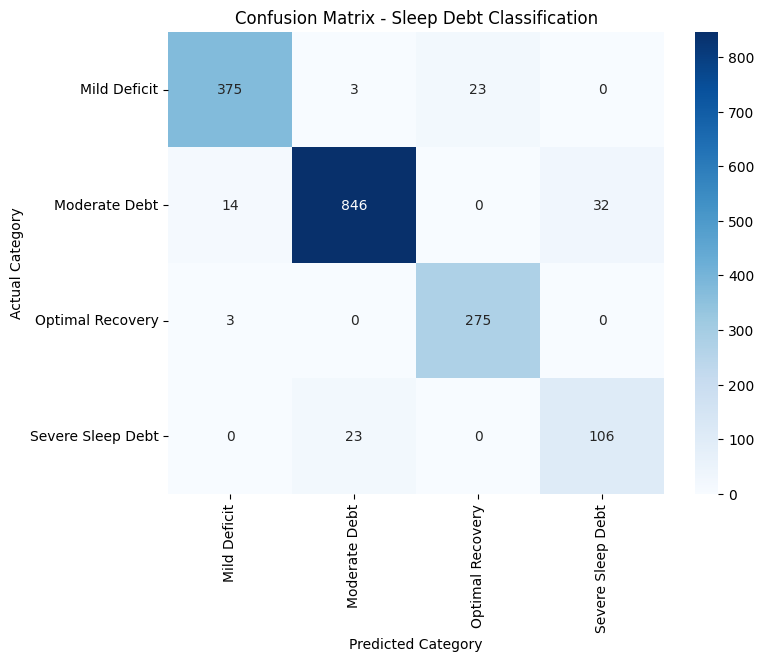

In [24]:
#confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.title(
    "Confusion Matrix - Sleep Debt Classification"
)

plt.show()

In [25]:
#classification report
print(
    classification_report(
        y_true,
        y_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

                   precision    recall  f1-score   support

     Mild Deficit       0.96      0.94      0.95       401
    Moderate Debt       0.97      0.95      0.96       892
 Optimal Recovery       0.92      0.99      0.95       278
Severe Sleep Debt       0.77      0.82      0.79       129

         accuracy                           0.94      1700
        macro avg       0.90      0.92      0.91      1700
     weighted avg       0.94      0.94      0.94      1700



In [26]:
def calculate_loss(model, loader):

    model.eval()

    total_loss = 0

    with torch.no_grad():

        for inputs, labels in loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            total_loss += loss.item() * inputs.size(0)

    return total_loss / len(loader.dataset)


train_loss = calculate_loss(model, train_loader)
val_loss = calculate_loss(model, val_loader)
test_loss = calculate_loss(model, test_loader)

print("Training Loss:", round(train_loss, 4))
print("Validation Loss:", round(val_loss, 4))
print("Testing Loss:", round(test_loss, 4))

Training Loss: 0.0287
Validation Loss: 0.1874
Testing Loss: 0.2334


###Ablation Study: Hyperparameters

Train models with different learning rates (e.g., 0.1, 0.01, 0.001).

In [27]:
def run_experiment(learning_rate, num_epochs=100):

    # Initialise a fresh model for each experiment
    model = SleepDebtNN(
        input_size,
        num_classes
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    train_losses = []
    val_losses = []

    best_val_loss = float("inf")
    best_model_state = None

    # Training loop
    for epoch in range(num_epochs):

        # Training
        model.train()

        running_train_loss = 0.0

        for inputs, labels in train_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_train_loss += (
                loss.item() * inputs.size(0)
            )

        epoch_train_loss = (
            running_train_loss / len(train_dataset)
        )

        # Validation
        model.eval()

        running_val_loss = 0.0

        with torch.no_grad():

            for inputs, labels in val_loader:

                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = model(inputs)

                loss = criterion(outputs, labels)

                running_val_loss += (
                    loss.item() * inputs.size(0)
                )

        epoch_val_loss = (
            running_val_loss / len(val_dataset)
        )

        train_losses.append(epoch_train_loss)
        val_losses.append(epoch_val_loss)

        # Save best model
        if epoch_val_loss < best_val_loss:

            best_val_loss = epoch_val_loss

            best_model_state = copy.deepcopy(
                model.state_dict()
            )

    # Restore best model
    model.load_state_dict(best_model_state)

    # Evaluate all three datasets
    train_acc, _, _ = evaluate_model(
        model, train_loader
    )

    val_acc, _, _ = evaluate_model(
        model, val_loader
    )

    test_acc, y_true, y_pred = evaluate_model(
        model, test_loader
    )

    # Calculate test loss
    test_loss = calculate_loss(
        model, test_loader
    )

    return {
        "learning_rate": learning_rate,
        "model": model,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "best_val_loss": best_val_loss,
        "train_accuracy": train_acc,
        "val_accuracy": val_acc,
        "test_accuracy": test_acc,
        "test_loss": test_loss,
        "epochs": len(train_losses)
    }

In [28]:
# train the three models
learning_rates = [0.1, 0.01, 0.001]

results = {}

for lr in learning_rates:

    print(f"\nTraining model with learning rate: {lr}")

    result = run_experiment(
        learning_rate=lr,
        num_epochs=100
    )

    results[lr] = result

    print(f"Best Validation Loss: {result['best_val_loss']:.4f}")
    print(f"Training Accuracy: {result['train_accuracy']*100:.2f}%")
    print(f"Validation Accuracy: {result['val_accuracy']*100:.2f}%")
    print(f"Testing Accuracy: {result['test_accuracy']*100:.2f}%")
    print(f"Test Loss: {result['test_loss']:.4f}")


Training model with learning rate: 0.1
Best Validation Loss: 0.0732
Training Accuracy: 96.82%
Validation Accuracy: 96.71%
Testing Accuracy: 95.76%
Test Loss: 0.0897

Training model with learning rate: 0.01
Best Validation Loss: 0.1083
Training Accuracy: 97.08%
Validation Accuracy: 95.18%
Testing Accuracy: 95.53%
Test Loss: 0.1113

Training model with learning rate: 0.001
Best Validation Loss: 0.0738
Training Accuracy: 98.82%
Validation Accuracy: 96.88%
Testing Accuracy: 96.24%
Test Loss: 0.0912


In [29]:
#compare results in a table
comparison = pd.DataFrame([
    {
        "Learning Rate": lr,
        "Best Validation Loss": results[lr]["best_val_loss"],
        "Training Accuracy": results[lr]["train_accuracy"],
        "Validation Accuracy": results[lr]["val_accuracy"],
        "Test Accuracy": results[lr]["test_accuracy"],
        "Test Loss": results[lr]["test_loss"]
    }
    for lr in learning_rates
])

display(
    comparison.style.format({
        "Best Validation Loss": "{:.4f}",
        "Training Accuracy": "{:.4f}",
        "Validation Accuracy": "{:.4f}",
        "Test Accuracy": "{:.4f}",
        "Test Loss": "{:.4f}"
    })
)


,Learning Rate,Best Validation Loss,Training Accuracy,Validation Accuracy,Test Accuracy,Test Loss
0,0.100000,0.0732,0.9682,0.9671,0.9576,0.0897
1,0.010000,0.1083,0.9708,0.9518,0.9553,0.1113
2,0.001000,0.0738,0.9882,0.9688,0.9624,0.0912


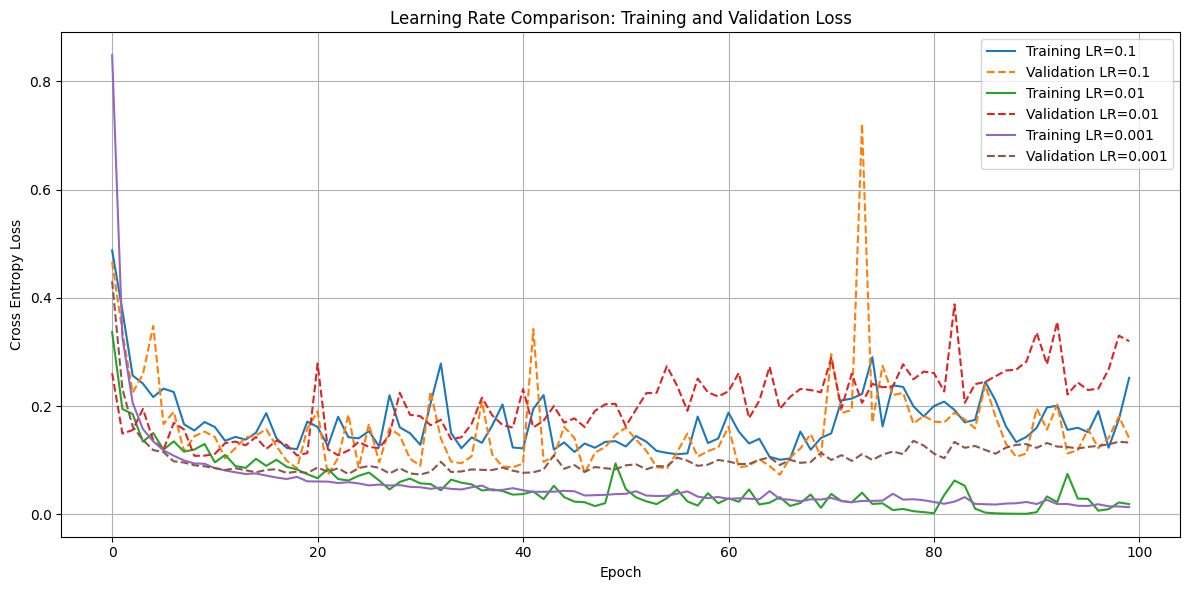

In [30]:
#training and validation loss
plt.figure(figsize=(12, 6))

for lr in learning_rates:

    plt.plot(
        results[lr]["train_losses"],
        label=f"Training LR={lr}"
    )

    plt.plot(
        results[lr]["val_losses"],
        linestyle="--",
        label=f"Validation LR={lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")

plt.title(
    "Learning Rate Comparison: Training and Validation Loss"
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


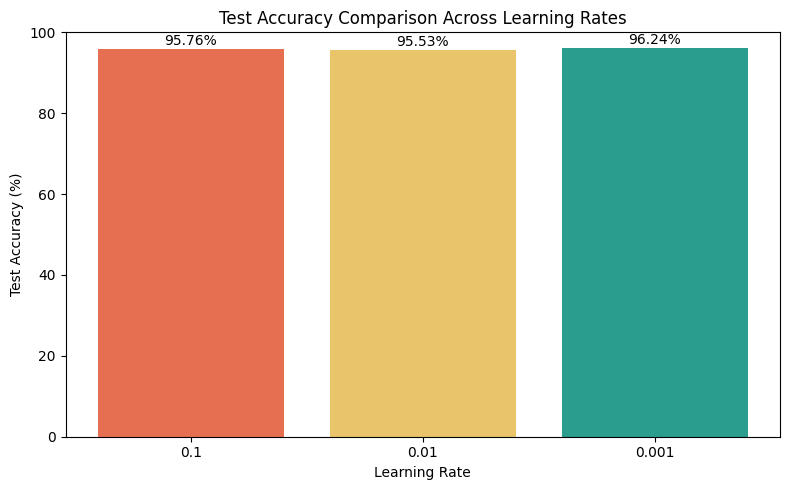

In [31]:
plt.figure(figsize=(8, 5))

accuracies = [
    results[lr]["test_accuracy"] * 100
    for lr in learning_rates
]

bars = plt.bar(
    [str(lr) for lr in learning_rates],
    accuracies,
    color=["#E76F51", "#E9C46A", "#2A9D8F"]
)

plt.xlabel("Learning Rate")
plt.ylabel("Test Accuracy (%)")

plt.title("Test Accuracy Comparison Across Learning Rates")

plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):

    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

Optionally test different numbers of hidden layers or neurons.

In [32]:
class FlexibleSleepDebtNN(nn.Module):

    def __init__(self, input_size, hidden_layers, num_classes):

        super(FlexibleSleepDebtNN, self).__init__()

        layers = []

        previous_size = input_size

        # Create hidden layers
        for neurons in hidden_layers:

            layers.append(
                nn.Linear(previous_size, neurons)
            )

            layers.append(nn.ReLU())

            previous_size = neurons

        # Output layer
        layers.append(
            nn.Linear(previous_size, num_classes)
        )

        self.network = nn.Sequential(*layers)

    def forward(self, x):

        return self.network(x)

In [33]:
# Model A
model_a = FlexibleSleepDebtNN(
    input_size, [32], num_classes
)

# Model B
model_b = FlexibleSleepDebtNN(
    input_size, [64, 32], num_classes
)

# Model C
model_c = FlexibleSleepDebtNN(
    input_size, [128, 64, 32], num_classes
)

In [34]:
def architecture_experiment(hidden_layers, num_epochs=100):

    model = FlexibleSleepDebtNN(
        input_size,
        hidden_layers,
        num_classes
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    train_losses = []
    val_losses = []

    best_val_loss = float("inf")
    best_model_state = None

    patience = 10
    counter = 0

    for epoch in range(num_epochs):

        # Training
        model.train()

        running_train_loss = 0.0

        for inputs, labels in train_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_train_loss += (
                loss.item() * inputs.size(0)
            )

        epoch_train_loss = (
            running_train_loss / len(train_dataset)
        )

        # Validation
        model.eval()

        running_val_loss = 0.0

        with torch.no_grad():

            for inputs, labels in val_loader:

                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = model(inputs)

                loss = criterion(outputs, labels)

                running_val_loss += (
                    loss.item() * inputs.size(0)
                )

        epoch_val_loss = (
            running_val_loss / len(val_dataset)
        )

        train_losses.append(epoch_train_loss)
        val_losses.append(epoch_val_loss)

        # Save best model
        if epoch_val_loss < best_val_loss:

            best_val_loss = epoch_val_loss

            best_model_state = copy.deepcopy(
                model.state_dict()
            )

            counter = 0

        else:

            counter += 1

        # Early stopping
        if counter >= patience:
            break

    # Restore best weights
    model.load_state_dict(best_model_state)

    # Evaluate model
    train_acc, _, _ = evaluate_model(
        model, train_loader
    )

    val_acc, _, _ = evaluate_model(
        model, val_loader
    )

    test_acc, y_true, y_pred = evaluate_model(
        model, test_loader
    )

    test_loss = calculate_loss(
        model, test_loader
    )

    return {
        "model": model,
        "hidden_layers": hidden_layers,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "best_val_loss": best_val_loss,
        "train_accuracy": train_acc,
        "val_accuracy": val_acc,
        "test_accuracy": test_acc,
        "test_loss": test_loss,
        "epochs": len(train_losses)
    }


In [35]:
architectures = {
    "Model A (32)": [32],
    "Model B (64, 32)": [64, 32],
    "Model C (128, 64, 32)": [128, 64, 32]
}

architecture_results = {}

for name, layers in architectures.items():

    print(f"\nTraining {name}")

    result = architecture_experiment(
        hidden_layers=layers,
        num_epochs=100
    )

    architecture_results[name] = result

    print("Best Validation Loss:",
          round(result["best_val_loss"], 4))

    print("Training Accuracy:",
          round(result["train_accuracy"] * 100, 2), "%")

    print("Validation Accuracy:",
          round(result["val_accuracy"] * 100, 2), "%")

    print("Test Accuracy:",
          round(result["test_accuracy"] * 100, 2), "%")

    print("Test Loss:",
          round(result["test_loss"], 4))



Training Model A (32)
Best Validation Loss: 0.0707
Training Accuracy: 98.51 %
Validation Accuracy: 96.82 %
Test Accuracy: 96.12 %
Test Loss: 0.0944

Training Model B (64, 32)
Best Validation Loss: 0.0744
Training Accuracy: 98.37 %
Validation Accuracy: 96.94 %
Test Accuracy: 95.94 %
Test Loss: 0.0947

Training Model C (128, 64, 32)
Best Validation Loss: 0.0853
Training Accuracy: 98.59 %
Validation Accuracy: 95.94 %
Test Accuracy: 95.94 %
Test Loss: 0.0974


In [36]:
architecture_comparison = pd.DataFrame([

    {
        "Architecture": name,

        "Best Validation Loss":
            result["best_val_loss"],

        "Training Accuracy":
            result["train_accuracy"],

        "Validation Accuracy":
            result["val_accuracy"],

        "Test Accuracy":
            result["test_accuracy"],

        "Test Loss":
            result["test_loss"],

        "Epochs":
            result["epochs"]
    }

    for name, result in architecture_results.items()

])

display(
    architecture_comparison.style.format({
        "Best Validation Loss": "{:.4f}",
        "Training Accuracy": "{:.4f}",
        "Validation Accuracy": "{:.4f}",
        "Test Accuracy": "{:.4f}",
        "Test Loss": "{:.4f}"
    })
)


,Architecture,Best Validation Loss,Training Accuracy,Validation Accuracy,Test Accuracy,Test Loss,Epochs
0,Model A (32),0.0707,0.9851,0.9682,0.9612,0.0944,83
1,"Model B (64, 32)",0.0744,0.9837,0.9694,0.9594,0.0947,31
2,"Model C (128, 64, 32)",0.0853,0.9859,0.9594,0.9594,0.0974,25


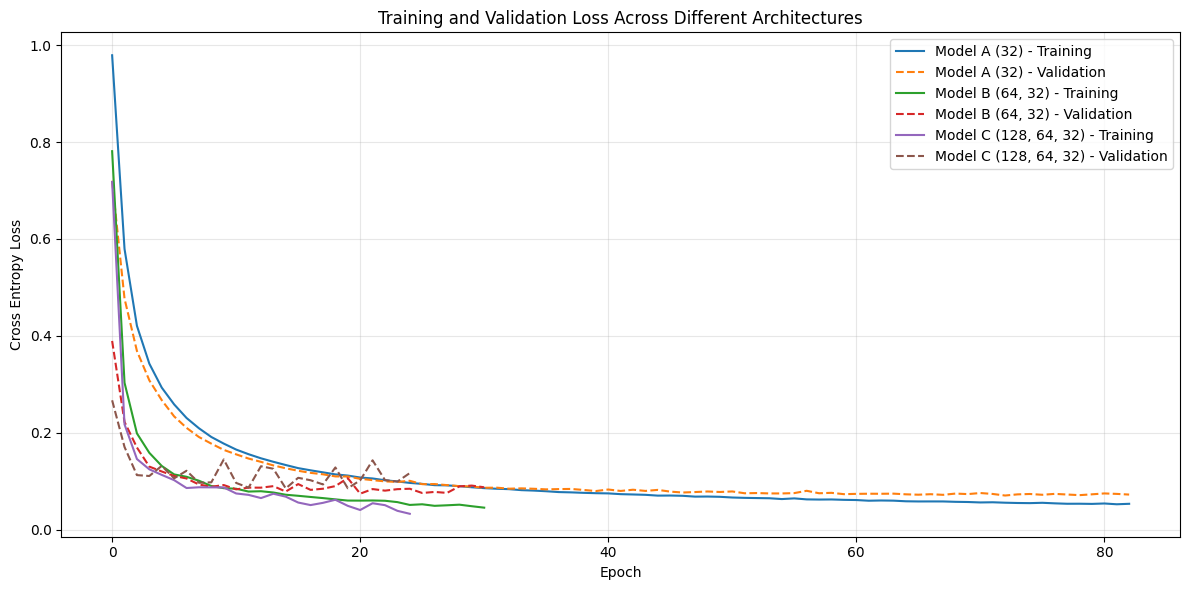

In [37]:
plt.figure(figsize=(12, 6))

for name, result in architecture_results.items():

    plt.plot(
        result["train_losses"],
        label=f"{name} - Training"
    )

    plt.plot(
        result["val_losses"],
        linestyle="--",
        label=f"{name} - Validation"
    )

plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")

plt.title(
    "Training and Validation Loss Across Different Architectures"
)

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


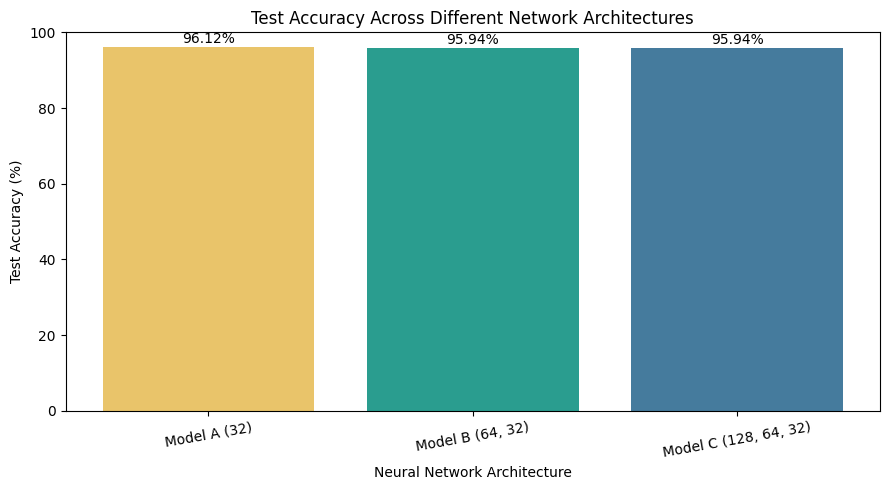

In [38]:

names = list(architecture_results.keys())

accuracies = [
    architecture_results[name]["test_accuracy"] * 100
    for name in names
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    names,
    accuracies,
    color=["#E9C46A", "#2A9D8F", "#457B9D"]
)

plt.ylabel("Test Accuracy (%)")
plt.xlabel("Neural Network Architecture")

plt.title("Test Accuracy Across Different Network Architectures")

plt.ylim(0, 100)

for bar, acc in zip(bars, accuracies):

    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f"{acc:.2f}%",
        ha="center"
    )

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


Extract successful and failed predictions

In [39]:
best_model = architecture_results[
    "Model A (32)"
]["model"]

best_model.eval()

with torch.no_grad():
    outputs = best_model(X_test_tensor.to(device))
    predictions = torch.argmax(outputs, dim=1).cpu().numpy()

# Create a results dataframe
case_study = X_test.reset_index(drop=True).copy()

case_study["Actual"] = label_encoder.inverse_transform(y_test)
case_study["Predicted"] = label_encoder.inverse_transform(predictions)

case_study["Correct"] = (
    case_study["Actual"] == case_study["Predicted"]
)

# Correct predictions
successful_cases = case_study[
    case_study["Correct"] == True
]

# Incorrect predictions
failed_cases = case_study[
    case_study["Correct"] == False
]

print("Successful predictions:")
display(successful_cases.head(5))

print("Failed predictions:")
display(failed_cases.head(5))

Successful predictions:


,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,Actual,Predicted,Correct
1,18,Female,Corporate 9-to-5,Night Owl,15,TikTok / Reels,69,0,35,40,19.5,5.48,21.3,21.9,3,Moderate Debt,Moderate Debt,True
2,19,Female,Corporate 9-to-5,Intermediate,71,Instagram / Reddit,71,0,242,46,70.8,6.97,17.8,15.5,4,Mild Deficit,Mild Deficit,True
3,28,Male,Healthcare / Shift Worker,Intermediate,4,TikTok / Reels,74,0,65,14,18.1,6.08,16.7,16.9,3,Moderate Debt,Moderate Debt,True
4,42,Female,Student,Morning Lark,26,Instagram / Reddit,53,0,47,38,31.0,9.28,24.5,18.9,0,Optimal Recovery,Optimal Recovery,True
6,27,Male,Remote Tech,Night Owl,71,TikTok / Reels,26,0,86,48,56.6,5.89,22.0,15.2,4,Moderate Debt,Moderate Debt,True


Failed predictions:


,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,Actual,Predicted,Correct
0,24,Male,Student,Intermediate,74,Messaging / Chat,80,1,133,74,61.7,6.73,21.8,16.5,4,Moderate Debt,Mild Deficit,False
5,25,Female,Corporate 9-to-5,Intermediate,135,Instagram / Reddit,81,0,0,29,73.7,4.69,18.2,17.9,6,Severe Sleep Debt,Moderate Debt,False
28,44,Male,Remote Tech,Intermediate,97,YouTube,100,0,250,16,84.9,5.54,15.3,17.7,6,Moderate Debt,Severe Sleep Debt,False
30,23,Male,Healthcare / Shift Worker,Intermediate,53,TikTok / Reels,53,0,146,76,55.0,5.04,21.4,13.9,5,Severe Sleep Debt,Moderate Debt,False
31,56,Female,Healthcare / Shift Worker,Night Owl,32,Messaging / Chat,57,0,0,43,45.3,3.57,22.9,16.7,5,Severe Sleep Debt,Moderate Debt,False


In [40]:
best_model.eval()
with torch.no_grad():
  outputs = best_model(X_test_tensor.to(device))
  probabilities = torch.softmax(outputs, dim=1)
  # Get the confidence (probability) of the predicted class
  confidences, predictions = torch.max(probabilities, dim=1)
  case_study["Confidence (%)"] = (confidences.cpu().numpy() * 100).round(2)

display(
  case_study[
  ["Actual", "Predicted", "Correct", "Confidence (%)"]
  ].head(10)
)

,Actual,Predicted,Correct,Confidence (%)
0,Moderate Debt,Mild Deficit,False,75.110001
1,Moderate Debt,Moderate Debt,True,100.000000
2,Mild Deficit,Mild Deficit,True,99.279999
3,Moderate Debt,Moderate Debt,True,100.000000
4,Optimal Recovery,Optimal Recovery,True,100.000000
5,Severe Sleep Debt,Moderate Debt,False,52.209999
6,Moderate Debt,Moderate Debt,True,100.000000
7,Mild Deficit,Mild Deficit,True,100.000000
8,Mild Deficit,Mild Deficit,True,99.570000
9,Mild Deficit,Mild Deficit,True,97.379997
